## **Cell 1: Imports and config**

In [1]:
%load_ext autoreload
%autoreload 2

import sys, time, json, random, datetime, importlib, inspect
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
assert (PROJECT_ROOT / "data").exists(), f"Wrong project root: {PROJECT_ROOT}"
sys.path.insert(0, str(PROJECT_ROOT))

CATEGORY = "metal_nut"
REPORT_DIR = PROJECT_ROOT / "reports" / "metrics"
FIG_DIR    = PROJECT_ROOT / "reports" / "figures"
MODEL_DIR  = PROJECT_ROOT / "models"
for d in (REPORT_DIR, FIG_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---------- Experiment settings ----------
IMAGE_SIZE  = 256
BATCH_SIZE  = 8
POOL_KERNEL = 3
SEED        = 42
BANK_RATIO  = 0.10
SIGMA       = 4.0

# ---------------- SWITCH ----------------
EMBED_MODE = "baseline"     # "baseline" | "concat"

if EMBED_MODE == "baseline":
    EMBED_DIM  = 1024
    TAG        = "baseline1024"
    EMB_PATH   = MODEL_DIR / f"{CATEGORY}_train_emb_baseline_1024.pt"
    CORESET_PT = MODEL_DIR / f"{CATEGORY}_coreset_indices_baseline1024.pt"
elif EMBED_MODE == "concat":
    EMBED_DIM  = 1536
    TAG        = "concat1536"
    EMB_PATH   = MODEL_DIR / f"{CATEGORY}_train_emb_concat_1536.pt"
    CORESET_PT = MODEL_DIR / f"{CATEGORY}_coreset_indices_concat1536.pt"
else:
    raise ValueError(f"Unknown EMBED_MODE: {EMBED_MODE}")

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device     : {device}")
print(f"EMBED_MODE : {EMBED_MODE}")
print(f"EMBED_DIM  : {EMBED_DIM}")
print(f"TAG        : {TAG}")
print(f"EMB_PATH   : {EMB_PATH.exists()}")
print(f"CORESET_PT : {CORESET_PT.exists()}")

Device     : cuda
EMBED_MODE : baseline
EMBED_DIM  : 1024
TAG        : baseline1024
EMB_PATH   : True
CORESET_PT : True


## **Cell 2: Write src/evaluation/metrics.py**

In [2]:
OVERWRITE = True

METRICS_CODE = r'''import numpy as np
from scipy import ndimage
from sklearn.metrics import roc_auc_score, average_precision_score


def image_metrics(labels, scores):
    """Image-level ranking quality. labels: 0/1, scores: higher = more anomalous."""
    return dict(
        image_auroc=float(roc_auc_score(labels, scores)),
        image_ap=float(average_precision_score(labels, scores)),
    )


def pixel_auroc(masks, maps):
    """Pixel-level AUROC over every pixel of every image."""
    return float(roc_auc_score(
        masks.reshape(-1).astype(np.uint8),
        maps.reshape(-1),
    ))


# Compatibility shim for NumPy 1.x and 2.x
_trapz = getattr(np, "trapezoid", None) or getattr(np, "trapz")


def auro(masks, maps, fpr_limit=0.3, n_points=201):
    """
    Area under the per-region-overlap (PRO) curve, normalized by fpr_limit.

    Reference: MVTec AD / Bergmann et al., "Uninformed Students" (CVPR 2020).

    Steps:
      1. Label connected defect regions.
      2. Sweep thresholds over the range of map values (low -> high).
      3. At each threshold compute:
         - FPR = fraction of normal pixels above threshold
         - PRO = mean fraction of each defect region above threshold
      4. Interpolate PRO onto a uniform FPR grid in [0, fpr_limit].
      5. Integrate over that grid and normalize by fpr_limit.
    """
    masks = masks.astype(bool)
    maps  = maps.astype(np.float64)

    # --- Label connected defect regions across all images ---
    reg = np.zeros(masks.shape, dtype=np.int32)
    n_reg = 0
    areas = []
    for i in range(masks.shape[0]):
        lbl, k = ndimage.label(masks[i])
        for j in range(1, k + 1):
            n_reg += 1
            reg[i][lbl == j] = n_reg
            areas.append(int((lbl == j).sum()))
    areas = np.array(areas, dtype=np.float64)

    if n_reg == 0:
        return 0.0

    in_reg        = reg > 0
    normal_pixels = (~masks).sum()
    if normal_pixels == 0:
        return 0.0

    lo, hi = float(maps.min()), float(maps.max())
    if hi == lo:
        return 0.0
    thresholds = np.linspace(lo, hi, n_points)

    fprs, pros = [], []
    for t in thresholds:
        pred = maps > t
        fp = (pred & ~masks).sum()
        fprs.append(fp / normal_pixels)
        hits = np.bincount(reg[pred & in_reg], minlength=n_reg + 1)[1:]
        pros.append((hits / areas).mean())

    fprs = np.asarray(fprs, dtype=np.float64)
    pros = np.asarray(pros, dtype=np.float64)

    fpr_grid = np.linspace(0.0, fpr_limit, n_points)
    order = np.argsort(fprs)
    fprs_sorted = fprs[order]
    pros_sorted = pros[order]

    pro_on_grid = np.interp(
        fpr_grid,
        fprs_sorted,
        pros_sorted,
        left=pros_sorted[0],
        right=pros_sorted[-1],
    )

    area = _trapz(pro_on_grid, fpr_grid)
    return float(area / fpr_limit)


def threshold_metrics(labels, scores, thr):
    """Confusion counts, precision, recall, F1 and FPR at a given threshold."""
    pred = scores > thr
    tp = int((pred  & (labels == 1)).sum())
    fp = int((pred  & (labels == 0)).sum())
    fn = int((~pred & (labels == 1)).sum())
    tn = int((~pred & (labels == 0)).sum())
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall    = tp / (tp + fn) if (tp + fn) else 0.0
    f1        = (2 * precision * recall / (precision + recall)
                 if (precision + recall) else 0.0)
    fpr       = fp / (fp + tn) if (fp + tn) else 0.0
    return dict(threshold=float(thr), tp=tp, fp=fp, fn=fn, tn=tn,
                precision=precision, recall=recall, f1=f1, fpr=fpr)


def mean_dice(masks, maps, labels, thr):
    """Mean Dice over defective images at a given threshold."""
    pred_all = maps > thr
    dices = []
    for i in range(len(labels)):
        if labels[i] != 1:
            continue
        gt = masks[i].astype(bool)
        pd = pred_all[i]
        inter = (gt & pd).sum()
        s = gt.sum() + pd.sum()
        dices.append(2 * inter / s if s > 0 else 0.0)
    return float(np.mean(dices)) if dices else 0.0
'''

# Ensure the evaluation package exists
pkg_init = PROJECT_ROOT / "src" / "evaluation" / "__init__.py"
pkg_init.parent.mkdir(parents=True, exist_ok=True)
pkg_init.write_text("", encoding="utf-8")

path = PROJECT_ROOT / "src" / "evaluation" / "metrics.py"
if path.exists() and not OVERWRITE:
    print("kept   :", path.relative_to(PROJECT_ROOT))
else:
    path.write_text(METRICS_CODE, encoding="utf-8")
    print("written:", path.relative_to(PROJECT_ROOT))

written: src\evaluation\metrics.py


## **Cell 3: Force Reload + Imports + AUPRO Validation on Synthetic Cases**

In [5]:
# ============================================================
# Cell 3 — Write corrected metrics.py + reload + validate AUPRO
# ============================================================
import sys, inspect
from pathlib import Path
import numpy as np

# ---------- STEP 1: Write the corrected metrics.py ----------
METRICS_PATH = PROJECT_ROOT / "src" / "evaluation" / "metrics.py"
METRICS_PATH.parent.mkdir(parents=True, exist_ok=True)

METRICS_CODE = r'''import numpy as np
from scipy import ndimage
from sklearn.metrics import roc_auc_score, average_precision_score


def image_metrics(labels, scores):
    return dict(
        image_auroc=float(roc_auc_score(labels, scores)),
        image_ap=float(average_precision_score(labels, scores)),
    )


def pixel_auroc(masks, maps):
    return float(roc_auc_score(
        masks.reshape(-1).astype(np.uint8),
        maps.reshape(-1),
    ))


_trapz = getattr(np, "trapezoid", None) or getattr(np, "trapz")


def auro(masks, maps, fpr_limit=0.3, n_points=201):
    """
    Area under the per-region-overlap (PRO) curve, normalized by fpr_limit.
    """
    masks = masks.astype(bool)
    maps  = maps.astype(np.float64)

    reg = np.zeros(masks.shape, dtype=np.int32)
    n_reg = 0
    areas = []
    for i in range(masks.shape[0]):
        lbl, k = ndimage.label(masks[i])
        for j in range(1, k + 1):
            n_reg += 1
            reg[i][lbl == j] = n_reg
            areas.append(int((lbl == j).sum()))
    areas = np.array(areas, dtype=np.float64)

    if n_reg == 0:
        return 0.0

    in_reg        = reg > 0
    normal_pixels = (~masks).sum()
    if normal_pixels == 0:
        return 0.0

    lo, hi = float(maps.min()), float(maps.max())
    if hi == lo:
        return 0.0

    thresholds = np.linspace(lo, hi, n_points)

    fprs, pros = [], []
    for t in thresholds:
        pred = maps > t
        fp = (pred & ~masks).sum()
        fprs.append(fp / normal_pixels)
        hits = np.bincount(reg[pred & in_reg], minlength=n_reg + 1)[1:]
        pros.append((hits / areas).mean())

    fprs = np.asarray(fprs, dtype=np.float64)
    pros = np.asarray(pros, dtype=np.float64)

    order = np.argsort(fprs, kind="stable")
    fprs = fprs[order]
    pros = pros[order]

    unique_fprs, unique_pros = [], []
    i = 0
    while i < len(fprs):
        j = i
        best = pros[i]
        while j + 1 < len(fprs) and fprs[j + 1] == fprs[i]:
            j += 1
            if pros[j] > best:
                best = pros[j]
        unique_fprs.append(fprs[i])
        unique_pros.append(best)
        i = j + 1

    unique_fprs = np.asarray(unique_fprs, dtype=np.float64)
    unique_pros = np.asarray(unique_pros, dtype=np.float64)

    fpr_grid = np.linspace(0.0, fpr_limit, n_points)

    if len(unique_fprs) == 1:
        pro_on_grid = np.full_like(fpr_grid, unique_pros[0])
    else:
        diffs = np.diff(unique_fprs)
        if (diffs <= 0).any():
            unique_fprs = unique_fprs + np.arange(len(unique_fprs)) * 1e-12
        pro_on_grid = np.interp(
            fpr_grid,
            unique_fprs,
            unique_pros,
            left=unique_pros[0],
            right=unique_pros[-1],
        )

    area = _trapz(pro_on_grid, fpr_grid)
    return float(area / fpr_limit)


def threshold_metrics(labels, scores, thr):
    pred = scores > thr
    tp = int((pred  & (labels == 1)).sum())
    fp = int((pred  & (labels == 0)).sum())
    fn = int((~pred & (labels == 1)).sum())
    tn = int((~pred & (labels == 0)).sum())
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall    = tp / (tp + fn) if (tp + fn) else 0.0
    f1        = (2 * precision * recall / (precision + recall)
                 if (precision + recall) else 0.0)
    fpr       = fp / (fp + tn) if (fp + tn) else 0.0
    return dict(threshold=float(thr), tp=tp, fp=fp, fn=fn, tn=tn,
                precision=precision, recall=recall, f1=f1, fpr=fpr)


def mean_dice(masks, maps, labels, thr):
    pred_all = maps > thr
    dices = []
    for i in range(len(labels)):
        if labels[i] != 1:
            continue
        gt = masks[i].astype(bool)
        pd = pred_all[i]
        inter = (gt & pd).sum()
        s = gt.sum() + pd.sum()
        dices.append(2 * inter / s if s > 0 else 0.0)
    return float(np.mean(dices)) if dices else 0.0
'''

METRICS_PATH.write_text(METRICS_CODE, encoding="utf-8")
print("STEP 1: written", METRICS_PATH)

# ---------- STEP 2: Purge + reload ----------
for mod_name in list(sys.modules.keys()):
    if mod_name.startswith("src"):
        del sys.modules[mod_name]

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src
from src.data.dataset import MVTecDataset, load_splits, IMAGENET_MEAN, IMAGENET_STD
from src.models.feature_extractor import (
    FeatureExtractor, extract_dataset, extract_dataset_concat
)
from src.models.patchcore import anomaly_maps, score_loader
from src.evaluation.metrics import (
    image_metrics, pixel_auroc, auro, threshold_metrics, mean_dice
)
import src.evaluation.metrics as em

mem_src = inspect.getsource(em.auro)
assert "if len(unique_fprs) == 1" in mem_src, "In-memory auro is stale!"
print("STEP 2: in-memory auro has the single-FPR fix")

# ---------- STEP 3: AUPRO validation ----------
print("\n" + "=" * 60)
print("STEP 3: AUPRO validation on synthetic cases")
print("=" * 60)

H, W = 64, 64

# Case 1 — perfect prediction
m = np.zeros((1, H, W), dtype=bool); m[0, 20:44, 20:44] = True
s = np.zeros((1, H, W)); s[0, 20:44, 20:44] = 10.0
a1 = auro(m, s, fpr_limit=0.3)
print(f"  Case 1 (perfect)        AUPRO = {a1:.4f}  (expect ~1.0)")
assert a1 > 0.95, f"Perfect case failed: {a1:.4f}"

# Case 2 — all-zero map
s0 = np.zeros((1, H, W))
a2 = auro(m, s0, fpr_limit=0.3)
print(f"  Case 2 (all-zero)       AUPRO = {a2:.4f}  (expect ~0.0)")
assert a2 < 0.05, f"All-zero case failed: {a2:.4f}"

# Case 3 — random noise
rng = np.random.default_rng(0)
s_noise = rng.random((1, H, W))
a3 = auro(m, s_noise, fpr_limit=0.3)
print(f"  Case 3 (random)         AUPRO = {a3:.4f}  (expect low)")

# Case 4 — two disjoint regions, both detected
m2 = np.zeros((1, H, W), dtype=bool)
m2[0, 10:20, 10:20] = True
m2[0, 40:50, 40:50] = True
s2 = np.zeros((1, H, W))
s2[0, 10:20, 10:20] = 10.0
s2[0, 40:50, 40:50] = 10.0
a4 = auro(m2, s2, fpr_limit=0.3)
print(f"  Case 4 (two regions)    AUPRO = {a4:.4f}  (expect ~1.0)")
assert a4 > 0.95, f"Two-region case failed: {a4:.4f}"

# Case 5 — half coverage
s3 = np.zeros((1, H, W))
s3[0, 10:20, 10:20] = 10.0
a5 = auro(m2, s3, fpr_limit=0.3)
print(f"  Case 5 (half covered)   AUPRO = {a5:.4f}  (expect ~0.5)")
assert 0.3 < a5 < 0.7, f"Partial coverage case failed: {a5:.4f}"

print("\n\u2713 AUPRO validated on all synthetic cases")

STEP 1: written c:\Users\ASUS\Desktop\AI_Projects\Industrial-defect-detection\src\evaluation\metrics.py
STEP 2: in-memory auro has the single-FPR fix

STEP 3: AUPRO validation on synthetic cases
  Case 1 (perfect)        AUPRO = 1.0000  (expect ~1.0)
  Case 2 (all-zero)       AUPRO = 0.0000  (expect ~0.0)
  Case 3 (random)         AUPRO = 0.1350  (expect low)
  Case 4 (two regions)    AUPRO = 1.0000  (expect ~1.0)
  Case 5 (half covered)   AUPRO = 0.5000  (expect ~0.5)

✓ AUPRO validated on all synthetic cases


## **Cell 4: Load Splits, Rebuild Bank, Score Test Set**

In [6]:
splits = load_splits(REPORT_DIR / f"{CATEGORY}_splits.csv", PROJECT_ROOT)
train_fit  = splits[splits.role == "fit"]
val_normal = splits[splits.role == "val_normal"]
test_df    = splits[splits.role == "test"]

assert (len(train_fit), len(val_normal), len(test_df)) == (198, 22, 115), \
    "Unexpected split sizes"
print("fit / val_normal / test:", len(train_fit), "/", len(val_normal), "/", len(test_df))

def make_loader(df):
    return DataLoader(
        MVTecDataset(df, IMAGE_SIZE),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True,
    )

test_ds = MVTecDataset(test_df, IMAGE_SIZE)

# ---------- Rebuild the memory bank from saved coreset indices ----------
ckpt = torch.load(CORESET_PT)
assert ckpt["embed_mode"] == EMBED_MODE, f"Coreset mode mismatch: {ckpt['embed_mode']}"
assert ckpt["embed_dim"]  == EMBED_DIM,  f"Coreset dim mismatch: {ckpt['embed_dim']}"
assert ckpt["seed"]       == SEED

train_emb = torch.load(EMB_PATH)
flat = train_emb.reshape(-1, EMBED_DIM)
assert flat.shape[0] == ckpt["n_total_patches"]

n_bank = int(BANK_RATIO * flat.shape[0])
bank = flat[ckpt["indices"][:n_bank]].to(device)
del train_emb, flat

# ---------- Score test + val ----------
extractor = FeatureExtractor().to(device)
KW = dict(embed_dim=EMBED_DIM, pool_kernel=POOL_KERNEL,
          sigma=SIGMA, embed_mode=EMBED_MODE)

test_loader = make_loader(test_df)
val_loader  = make_loader(val_normal)

# Warmup
for _ in range(3):
    _ = score_loader(extractor, bank, test_loader, device, **KW)

if device.type == "cuda":
    torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats()

t0 = time.perf_counter()
res_test = score_loader(extractor, bank, test_loader, device, **KW)
if device.type == "cuda":
    torch.cuda.synchronize()
latency_ms = 1000 * (time.perf_counter() - t0) / len(test_df)
peak_mb    = torch.cuda.max_memory_allocated() / 1e6

res_val = score_loader(extractor, bank, val_loader, device, **KW)

assert list(res_test["paths"]) == list(test_df["path"]), "Order mismatch"

s_val  = res_val["scores"].numpy()
s_test = res_test["scores"].numpy()
y_test = res_test["labels"].numpy()
t_test = np.array(res_test["defect_types"])
masks_np = res_test["masks"].numpy() > 0.5
maps_np  = res_test["maps"].numpy()

print(f"bank {tuple(bank.shape)} | latency {latency_ms:.1f} ms/image | peak {peak_mb:.0f} MB")
print(f"image AUROC (sanity check): "
      f"{image_metrics(y_test, s_test)['image_auroc']:.4f}")

fit / val_normal / test: 198 / 22 / 115
bank (20275, 1024) | latency 47.1 ms/image | peak 432 MB
image AUROC (sanity check): 0.9995


## **Cell 5: Dev/Final Split + Metrics by Subset + Per-Defect**

In [7]:
# ---------- Fixed stratified dev/final split ----------
rng = np.random.default_rng(SEED)
role = np.empty(len(t_test), dtype=object)
for g in np.unique(t_test):
    idx = rng.permutation(np.where(t_test == g)[0])
    half = len(idx) // 2
    role[idx[:half]] = "dev"
    role[idx[half:]] = "final"

print(f"dev half images   : {(role == 'dev').sum()}")
print(f"final half images : {(role == 'final').sum()}")

def compute_subset_metrics(mask, name):
    if mask.sum() == 0:
        return None
    lbl = y_test[mask]
    sc  = s_test[mask]
    msk = masks_np[mask]
    mps = maps_np[mask]
    out = {"subset": name, "n_images": int(mask.sum())}
    out.update(image_metrics(lbl, sc))
    out["pixel_auroc"] = pixel_auroc(msk, mps)
    out["aupro"]       = auro(msk, mps)
    return out

rows = []
rows.append(compute_subset_metrics(np.ones_like(y_test, dtype=bool), "all test"))
rows.append(compute_subset_metrics(role == "dev",   "dev half"))
rows.append(compute_subset_metrics(role == "final", "final half"))
for d in ["bent", "color", "flip", "scratch"]:
    m = (t_test == d) | (t_test == "good")
    rows.append(compute_subset_metrics(m, f"{d} (+ good)"))

metrics_df = pd.DataFrame(rows)
print("\n" + "=" * 78)
print("Metrics by subset")
print("=" * 78)
print(metrics_df.round(4).to_string(index=False))
metrics_df.to_csv(REPORT_DIR / f"{CATEGORY}_metrics_by_subset_{TAG}.csv", index=False)

# ---------- Per-defect-only metrics ----------
print("\n" + "=" * 78)
print("Per-defect-only metrics")
print("=" * 78)
per_defect = []
for d in ["bent", "color", "flip", "scratch"]:
    m = (t_test == d) | (t_test == "good")
    per_defect.append(compute_subset_metrics(m, d))
per_df = pd.DataFrame(per_defect)
print(per_df.round(4).to_string(index=False))
per_df.to_csv(REPORT_DIR / f"{CATEGORY}_per_defect_{TAG}.csv", index=False)

dev half images   : 56
final half images : 59

Metrics by subset
          subset  n_images  image_auroc  image_ap  pixel_auroc  aupro
        all test       115       0.9995    0.9999       0.9888 0.9378
        dev half        56       0.9980    0.9995       0.9885 0.9309
      final half        59       1.0000    1.0000       0.9891 0.9449
   bent (+ good)        47       1.0000    1.0000       0.9960 0.9808
  color (+ good)        44       1.0000    1.0000       0.9952 0.9854
   flip (+ good)        45       1.0000    1.0000       0.9874 0.9579
scratch (+ good)        45       0.9980    0.9982       0.9783 0.9260

Per-defect-only metrics
 subset  n_images  image_auroc  image_ap  pixel_auroc  aupro
   bent        47        1.000    1.0000       0.9960 0.9808
  color        44        1.000    1.0000       0.9952 0.9854
   flip        45        1.000    1.0000       0.9874 0.9579
scratch        45        0.998    0.9982       0.9783 0.9260


## **Cell 6: Threshold Policies**

In [8]:
policies = {
    "max of val normals":   float(s_val.max()),
    "val mean + 2 std":     float(s_val.mean() + 2 * s_val.std()),
    "val mean + 3 std":     float(s_val.mean() + 3 * s_val.std()),
    "val 95th percentile":  float(np.quantile(s_val, 0.95)),
    "val 99th percentile":  float(np.quantile(s_val, 0.99)),
}

rows = []
for name, thr in policies.items():
    r = threshold_metrics(y_test, s_test, thr)
    r["mean_dice_defective"] = mean_dice(masks_np, maps_np, y_test, thr)
    r["policy"] = name
    rows.append(r)

thr_df = pd.DataFrame(rows)[
    ["policy", "threshold", "tp", "fp", "fn", "tn",
     "precision", "recall", "f1", "fpr", "mean_dice_defective"]
].round(4)

print("Threshold policies (derived from held-out normals only):")
print(thr_df.to_string(index=False))
thr_df.to_csv(REPORT_DIR / f"{CATEGORY}_threshold_policies_{TAG}.csv", index=False)

CHOSEN_POLICY = "max of val normals"
THRESH = float(policies[CHOSEN_POLICY])
print(f"\nChosen policy: {CHOSEN_POLICY}  ->  THRESH = {THRESH:.4f}")
print("Justification: conservative baseline; does not use any test data.")

Threshold policies (derived from held-out normals only):
             policy  threshold  tp  fp  fn  tn  precision  recall     f1    fpr  mean_dice_defective
 max of val normals     1.1666  93   2   0  20     0.9789  1.0000 0.9894 0.0909               0.6892
   val mean + 2 std     1.1958  93   2   0  20     0.9789  1.0000 0.9894 0.0909               0.6951
   val mean + 3 std     1.2625  90   0   3  22     1.0000  0.9677 0.9836 0.0000               0.6844
val 95th percentile     1.1532  93   2   0  20     0.9789  1.0000 0.9894 0.0909               0.6845
val 99th percentile     1.1638  93   2   0  20     0.9789  1.0000 0.9894 0.0909               0.6884

Chosen policy: max of val normals  ->  THRESH = 1.1666
Justification: conservative baseline; does not use any test data.


## **Cell 7: ROC / PR / Pixel-ROC Curves**

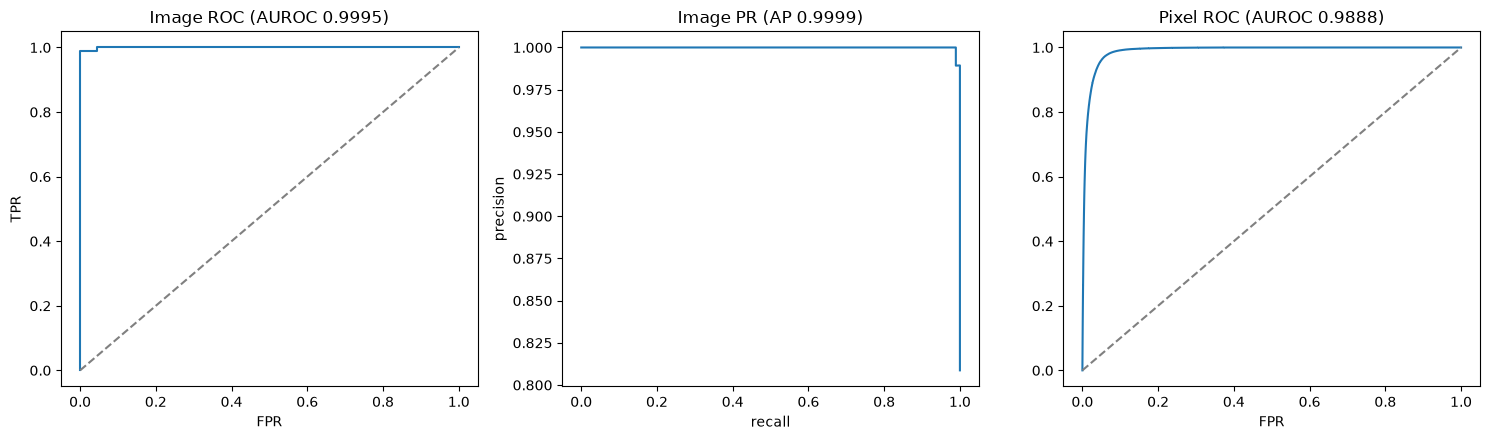

In [9]:
from sklearn.metrics import roc_curve, precision_recall_curve

row_all = metrics_df.iloc[0]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

fpr, tpr, _ = roc_curve(y_test, s_test)
axes[0].plot(fpr, tpr)
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_title(f"Image ROC (AUROC {row_all.image_auroc:.4f})")
axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR")

prec, rec, _ = precision_recall_curve(y_test, s_test)
axes[1].plot(rec, prec)
axes[1].set_title(f"Image PR (AP {row_all.image_ap:.4f})")
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision")

step = 7
pf, pt, _ = roc_curve(
    masks_np.reshape(-1)[::step].astype(np.uint8),
    maps_np.reshape(-1)[::step],
)
axes[2].plot(pf, pt)
axes[2].plot([0, 1], [0, 1], "--", color="gray")
axes[2].set_title(f"Pixel ROC (AUROC {row_all.pixel_auroc:.4f})")
axes[2].set_xlabel("FPR")

plt.tight_layout()
plt.savefig(FIG_DIR / f"{CATEGORY}_eval_curves_{TAG}.png", dpi=150)
plt.show()

## **Cell 8: Error Analysis (FP + Misses)**

false positives: 2 | misses: 0


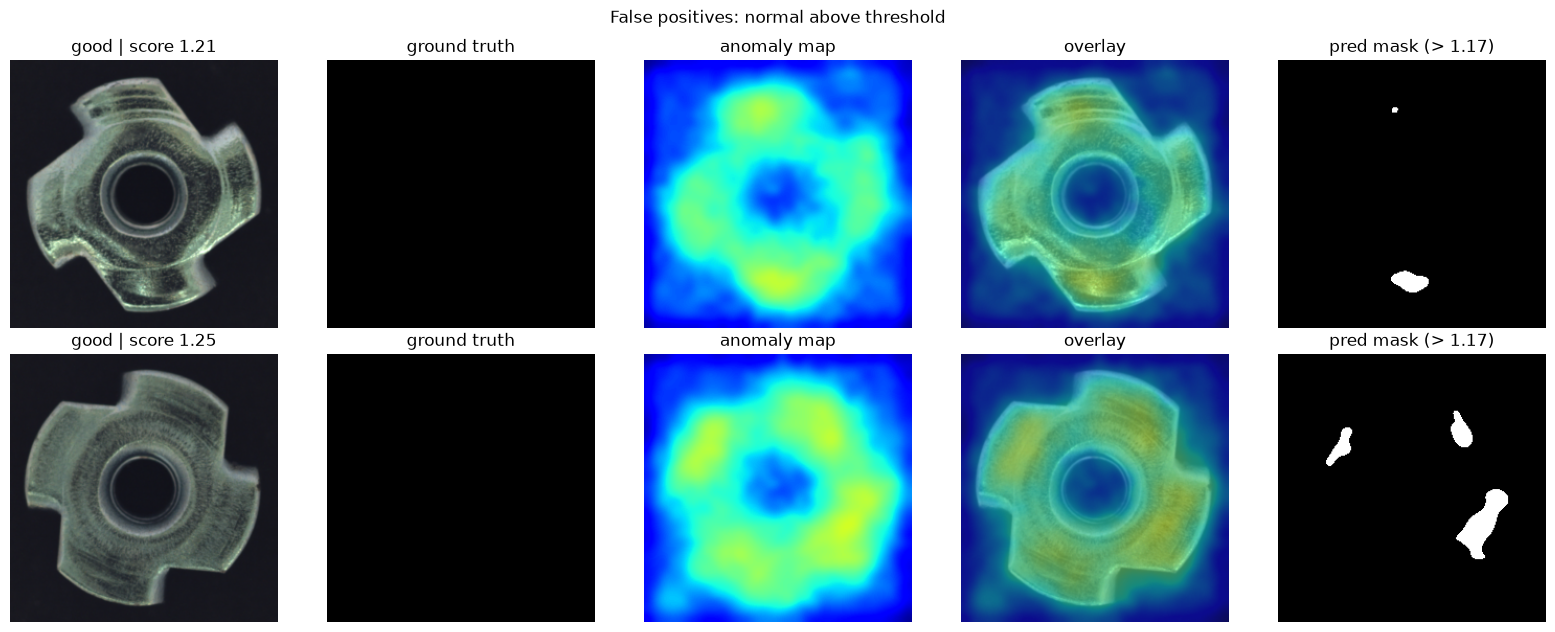

[Misses: defective below threshold] no cases


In [10]:
mean_ = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std_  = torch.tensor(IMAGENET_STD).view(3, 1, 1)

def denorm(t):
    return (t * std_ + mean_).clamp(0, 1).permute(1, 2, 0).numpy()

vmin, vmax = float(maps_np.min()), float(maps_np.max())

def show_cases(indices, title, fname):
    if len(indices) == 0:
        print(f"[{title}] no cases")
        return
    fig, axes = plt.subplots(len(indices), 5, figsize=(16, 3.2 * len(indices)))
    axes = np.atleast_2d(axes)
    for row, i in zip(axes, indices):
        img  = denorm(test_ds[i]["image"])
        gt   = masks_np[i]
        amap = maps_np[i]
        row[0].imshow(img); row[0].set_title(f"{t_test[i]} | score {s_test[i]:.2f}")
        row[1].imshow(gt, cmap="gray"); row[1].set_title("ground truth")
        row[2].imshow(amap, cmap="jet", vmin=vmin, vmax=vmax); row[2].set_title("anomaly map")
        row[3].imshow(img); row[3].imshow(amap, cmap="jet", alpha=0.5, vmin=vmin, vmax=vmax)
        row[3].set_title("overlay")
        row[4].imshow(amap > THRESH, cmap="gray")
        row[4].set_title(f"pred mask (> {THRESH:.2f})")
        for a in row: a.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(FIG_DIR / fname, dpi=130)
    plt.show()

fp_idx = np.where((y_test == 0) & (s_test > THRESH))[0]
fn_idx = np.where((y_test == 1) & (s_test <= THRESH))[0]

print(f"false positives: {len(fp_idx)} | misses: {len(fn_idx)}")

show_cases(list(fp_idx), "False positives: normal above threshold",
           f"{CATEGORY}_false_positives_{TAG}.png")
show_cases(list(fn_idx), "Misses: defective below threshold",
           f"{CATEGORY}_misses_{TAG}.png")

## **Cell 9: Save Final Report + Metadata**

In [11]:
chosen = thr_df[thr_df.policy == CHOSEN_POLICY].iloc[0]
row_all = metrics_df.iloc[0]

report = pd.DataFrame([dict(
    model="patchcore_wrn50",
    category=CATEGORY,
    embed_mode=EMBED_MODE,
    embed_dim=EMBED_DIM,
    split="all test",
    bank_ratio=BANK_RATIO,
    bank_patches=int(bank.shape[0]),
    sigma=SIGMA,
    image_size=IMAGE_SIZE,
    pool_kernel=POOL_KERNEL,
    image_auroc=row_all.image_auroc,
    image_ap=row_all.image_ap,
    pixel_auroc=row_all.pixel_auroc,
    auro=row_all.aupro,
    precision=chosen.precision,
    recall=chosen.recall,
    f1=chosen.f1,
    threshold=chosen.threshold,
    threshold_policy=CHOSEN_POLICY,
    latency_ms=round(latency_ms, 1),
    peak_gpu_memory_mb=round(peak_mb, 1),
)])

report.to_csv(REPORT_DIR / f"{CATEGORY}_patchcore_results_{TAG}.csv", index=False)

meta = {
    "date":             str(datetime.date.today()),
    "gpu":              torch.cuda.get_device_name(0),
    "torch":            torch.__version__,
    "numpy":            np.__version__,
    "backbone":         "wide_resnet50_2 layer2+layer3 (frozen)",
    "embed_mode":       EMBED_MODE,
    "embed_dim":        EMBED_DIM,
    "bank_patches":     int(bank.shape[0]),
    "bank_ratio":       BANK_RATIO,
    "sigma":            SIGMA,
    "image_size":       IMAGE_SIZE,
    "pool_kernel":      POOL_KERNEL,
    "seed":             SEED,
    "threshold_policy": CHOSEN_POLICY,
    "threshold":        float(THRESH),
    "eval_note": (
        "Threshold from 22 held-out normal images — provisional, "
        "not a guaranteed production false-alarm rate. "
        "Benchmark contains only the metal_nut category. "
        "Dev/final split is exploratory; a truly untouched test set "
        "would require a fresh data source."
    ),
    "aupro_validated":  True,
}
with open(REPORT_DIR / f"{CATEGORY}_eval_meta_{TAG}.json", "w") as f:
    json.dump(meta, f, indent=2)

print(json.dumps(meta, indent=2))
print(f"\nSaved all evaluation outputs for {TAG}")

{
  "date": "2026-10-13",
  "gpu": "NVIDIA GeForce RTX 3050 Laptop GPU",
  "torch": "2.7.1+cu118",
  "numpy": "2.4.6",
  "backbone": "wide_resnet50_2 layer2+layer3 (frozen)",
  "embed_mode": "baseline",
  "embed_dim": 1024,
  "bank_patches": 20275,
  "bank_ratio": 0.1,
  "sigma": 4.0,
  "image_size": 256,
  "pool_kernel": 3,
  "seed": 42,
  "threshold_policy": "max of val normals",
  "threshold": 1.16659677028656,
  "eval_note": "Threshold from 22 held-out normal images \u2014 provisional, not a guaranteed production false-alarm rate. Benchmark contains only the metal_nut category. Dev/final split is exploratory; a truly untouched test set would require a fresh data source.",
  "aupro_validated": true
}

Saved all evaluation outputs for baseline1024
